# Human fib/dec pseudotime — start to finish

**Input:** `data/deliverables/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad` (the current human fib/dec object;
QC'd coordinates — degenerate-only for human, by decision — and `tissue_section`, synced 2026-09-02). 47,533 cells.

**How this differs from the mouse notebook.** Human has **no apoptotic label** (so no drop step; all cells kept),
only **two subtypes** (`endometrial_fibroblast` → `decidual_cell`) and **two timepoints** (`secretory` → `menstrual`,
in that biological order — decidualization happens in secretory, shedding in menstrual). The subtype gate is therefore
a two-level ordering, and the "root-pinning" failure mode cannot arise. §5 optionally joins the human decidual
subclusters (4 stable clusters at res 0.3, from `human_dec_subclusters.csv`) for finer violins if that file is present.

**Steps:** load → scVI → neighbours / UMAP / diffmap → **you choose the root** (§5) → DPT + Palantir → quantile
normalisation → violins → spatial plots. **Run on a GPU node** (`--gres=gpu:1 --mem 200G --cpus-per-task 8`, `rsc_uv`).

Same conventions as mouse: Palantir with **`use_early_cell_as_start=True`** (palantir 1.4.5 otherwise re-picks its
own start); DC sign measured not assumed; wrong orientation **REFUSED, never flipped**. Nothing modifies the deliverable.

The object already carries a `dpt_pseudotime` from the Aug-29 moscot/CellRank run (ρ(pt, day) = +0.313, flagged as
modest in its own provenance string). §6 reports its agreement with the new pseudotime but does not use it.

In [1]:
import pathlib, json, h5py, warnings, os
import numpy as np, pandas as pd, scanpy as sc, anndata as ad
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
warnings.filterwarnings("ignore"); sc.settings.verbosity = 1
try:    from anndata.io import read_elem
except ImportError: from anndata.experimental import read_elem

X   = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final")
SRC = X/"data/deliverables/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad"
ISO = X/"results/isodepth/human_fibdec_isodepth.h5ad"
SUBCL = X/"results/human_dec_subclusters.csv"   # optional: 4 decidual subclusters (res 0.3); joined in section 5 if present
OUT = X/"results/pseudotime_human_final"; OUT.mkdir(parents=True, exist_ok=True)
SEED = 0

# human has two subtypes and two phases; biological order secretory (decidualizing) -> menstrual (shedding)
SUBORDER = ["endometrial_fibroblast", "decidual_cell"]
TPORDER  = ["secretory", "menstrual"]
RANK, TPRANK = {s:i for i,s in enumerate(SUBORDER)}, {t:i for i,t in enumerate(TPORDER)}
PAL  = dict(zip(SUBORDER, sns.color_palette("viridis", len(SUBORDER))))
TPAL = dict(zip(TPORDER,  sns.color_palette("rocket_r", len(TPORDER))))

CHECKS = []
def verify(label, got, want=True, note=""):
    ok = bool(got) if isinstance(want, bool) else (got == want)
    CHECKS.append((label, ok, str(got), note))
    print(("PASS  " if ok else "FAIL  ") + label + f"   [{got}]" + (f"  {note}" if note else "")); return ok
print("source:", SRC.name, "| exists:", SRC.exists())

source: 2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad | exists: True


## 1 — load (no cells dropped: human has no apoptotic label)

In [2]:
a = sc.read_h5ad(SRC)
for c in ("cell_subtype","timepoint","sample"): a.obs[c] = a.obs[c].astype(str)
print("loaded", a.shape, "| layers:", list(a.layers), "| obsm:", list(a.obsm))
verify("counts layer present (scVI input)", "counts" in a.layers)
verify("QC'd coordinates + tissue_section present", {"x_um_qc","y_um_qc","tissue_section"} <= set(a.obs.columns))
verify("subtypes are exactly the two expected", set(a.obs.cell_subtype) == set(SUBORDER), note=str(set(a.obs.cell_subtype)))
verify("timepoints are exactly the two expected", set(a.obs.timepoint) == set(TPORDER), note=str(set(a.obs.timepoint)))
print("\nsubtype x timepoint:"); display(pd.crosstab(a.obs.cell_subtype, a.obs.timepoint).reindex(index=SUBORDER, columns=TPORDER))
print("per sample:", a.obs["sample"].value_counts().to_dict())
if "dpt_pseudotime" in a.obs: a.obs = a.obs.rename(columns={"dpt_pseudotime": "dpt_pseudotime_aug29"})   # keep the old one out of the way

loaded (47533, 36601) | layers: ['counts'] | obsm: ['X_scVI', 'X_scVI_wholetissue', 'X_spatial', 'X_umap_scVI', 'X_umap_wholetissue']
PASS  counts layer present (scVI input)   [True]
PASS  QC'd coordinates + tissue_section present   [True]
PASS  subtypes are exactly the two expected   [True]  {'decidual_cell', 'endometrial_fibroblast'}
PASS  timepoints are exactly the two expected   [True]  {'menstrual', 'secretory'}

subtype x timepoint:


timepoint,secretory,menstrual
cell_subtype,,
endometrial_fibroblast,17891,7994
decidual_cell,5550,16098


per sample: {'secretory_mck6a': 9122, 'secretory_mck6b': 8926, 'menstrual_mck5b': 8361, 'menstrual_mck5a': 8237, 'menstrual_mck5c': 7494, 'secretory_mck6c': 5393}


## 2 — HVGs on counts (2,000 seurat_v3, batch = `sample`)

In [4]:
HVG, N_LATENT, EPOCHS = 3000, 30, 200
# house standard (2026-09-10): mito/ribo genes are excluded from the HVG candidate pool,
# matching pipeline stages 02_integrate / 04b_reintegrate (same prefix lists). scVI itself
# remains batch-aware. NOTE: the cached embedding.h5ad is reloaded if present -- this patch
# changes nothing until that cache is renamed/removed and the notebook re-run.
a.var["mito"] = a.var_names.str.startswith(("mt-", "Mt-", "MT-"))
a.var["ribo"] = a.var_names.str.startswith(("Rps", "Rpl", "Mrps", "Mrpl", "RPS", "RPL", "MRPS", "MRPL"))
print(f"HVG candidate pool: excluding {int(a.var.mito.sum())} mito + {int(a.var.ribo.sum())} ribo genes")
a_hvg = a[:, (~a.var["mito"]) & (~a.var["ribo"])].copy()
sc.pp.highly_variable_genes(a_hvg, n_top_genes=HVG, flavor="seurat_v3", layer="counts", batch_key="sample")
a.var["highly_variable"] = a.var_names.isin(a_hvg.var_names[a_hvg.var["highly_variable"]])
del a_hvg
av = a[:, a.var["highly_variable"]].copy()
print("HVG matrix:", av.shape)

HVG matrix: (47533, 3000)


## 3 — scVI (GPU) → neighbours → UMAP → diffmap

Reloads `embedding.h5ad` on re-run so root choices are made on a fixed embedding.

Seed set to 0


PASS  GPU visible to torch   [True]  scVI on CPU for 42k cells x 200 epochs is hours


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A100-SXM4-80GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Training:   0%|          | 0/200 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=200` reached.


embedding saved to /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/pseudotime_human_final/embedding.h5ad
X_scVI (47533, 30) | X_diffmap (47533, 15) -> DC1..DC14 = columns 1..14


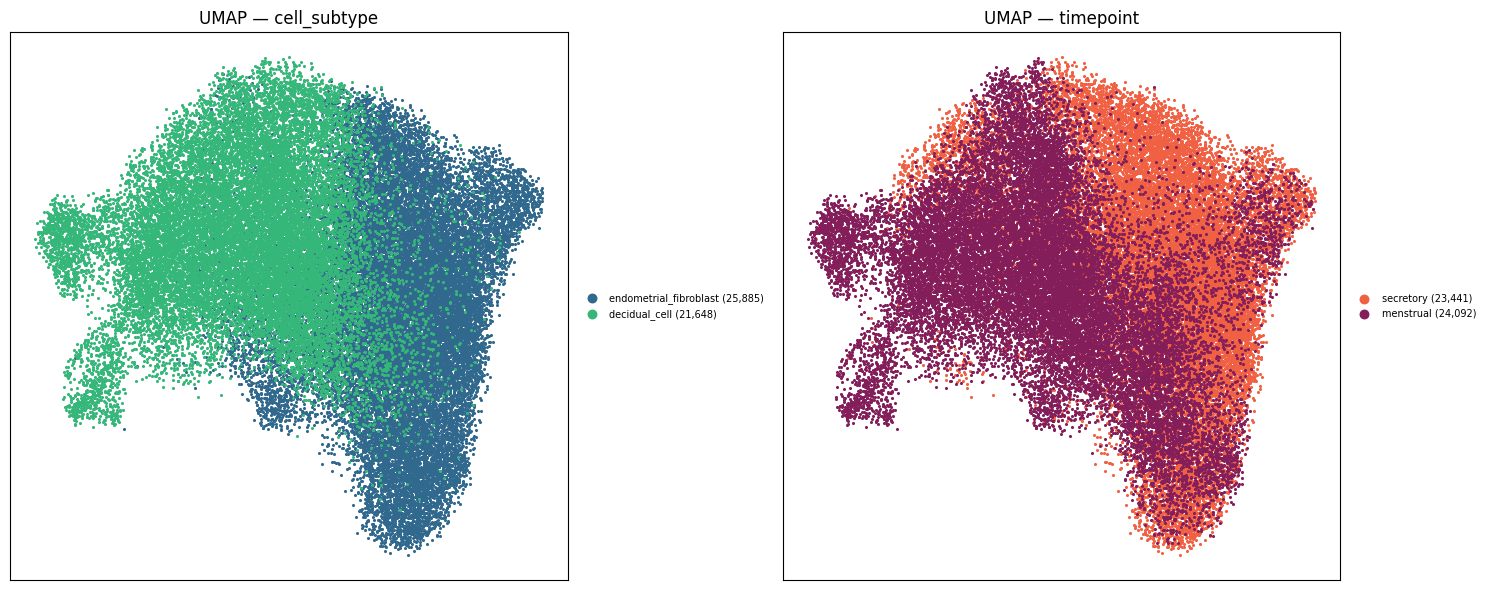

In [5]:
EMB = OUT/"embedding.h5ad"
if EMB.exists():
    e = sc.read_h5ad(EMB)
    assert (e.obs_names == a.obs_names).all(), "saved embedding was built on a different cell set — delete embedding.h5ad to retrain"
    for k in ("X_scVI","X_umap","X_diffmap"): a.obsm[k] = e.obsm[k]
    for k in ("connectivities","distances"): a.obsp[k] = e.obsp[k]
    for k in ("neighbors","diffmap_evals","scvi"): a.uns[k] = e.uns[k]
    print("reloaded embedding from", EMB.name, "| trained:", a.uns["scvi"].get("trained_at"))
else:
    import scvi, torch, datetime
    verify("GPU visible to torch", torch.cuda.is_available(), note="scVI on CPU for 42k cells x 200 epochs is hours")
    scvi.settings.seed = SEED
    scvi.model.SCVI.setup_anndata(av, layer="counts", batch_key="sample")
    model = scvi.model.SCVI(av, n_latent=N_LATENT)
    model.train(max_epochs=EPOCHS)
    a.obsm["X_scVI"] = model.get_latent_representation(av)
    a.uns["scvi"] = dict(n_latent=N_LATENT, epochs=EPOCHS, hvg=HVG, batch_key="sample", seed=SEED,
                     exclude_mito_ribo=True,
                         source=str(SRC), dropped="none (human has no apoptotic label)", trained_at=datetime.datetime.now().isoformat())
    sc.pp.neighbors(a, use_rep="X_scVI", n_neighbors=15, random_state=SEED)
    sc.tl.umap(a, random_state=SEED)
    sc.tl.diffmap(a, n_comps=15)
    e = ad.AnnData(obs=a.obs[["cell_subtype","timepoint","sample"]].copy())
    for k in ("X_scVI","X_umap","X_diffmap"): e.obsm[k] = a.obsm[k]
    for k in ("connectivities","distances"): e.obsp[k] = a.obsp[k]
    for k in ("neighbors","diffmap_evals","scvi"): e.uns[k] = a.uns[k]
    e.write_h5ad(EMB); print("embedding saved to", EMB)
O, DM = a.obs, a.obsm["X_diffmap"]; NDC = DM.shape[1] - 1
print("X_scVI", a.obsm["X_scVI"].shape, "| X_diffmap", DM.shape, "-> DC1..DC%d = columns 1..%d" % (NDC, NDC))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (cmap_, col) in zip(axes, ((PAL,"cell_subtype"), (TPAL,"timepoint"))):
    for cat in [s for s in (SUBORDER if col=="cell_subtype" else TPORDER) if s in set(O[col])]:
        m = (O[col]==cat).to_numpy(); ax.scatter(a.obsm["X_umap"][m,0], a.obsm["X_umap"][m,1], s=1.5, c=[cmap_[cat]], label=f"{cat} ({m.sum():,})", rasterized=True)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"UMAP — {col}"); ax.legend(fontsize=7, markerscale=5, loc="center left", bbox_to_anchor=(1.01,.5), frameon=False)
fig.tight_layout()

## 4 — which DC, and which end, is the early end?

With two subtypes the `spearman(DC, rank)` is a point-biserial fib-vs-dec separation; the sign still tells you which end is the fibroblast pole.

,rho_subtype_rank,early_end,low_tail,high_tail
DC,,,,
DC1,0.771,min,"endometrial_fibroblast 100% | secretory 80%,...","decidual_cell 100%, endometrial_fibroblast 0% ..."
DC2,0.702,min,"decidual_cell 87%, endometrial_fibroblast 13% ...","decidual_cell 100% | menstrual 100%, secreto..."
DC3,-0.670,max,"decidual_cell 100% | menstrual 64%, secretor...","decidual_cell 95%, endometrial_fibroblast 5% ..."
DC4,0.038,min,"endometrial_fibroblast 100%, decidual_cell 0% ...","endometrial_fibroblast 99%, decidual_cell 1% ..."
DC5,0.170,min,"endometrial_fibroblast 63%, decidual_cell 37% ...","decidual_cell 89%, endometrial_fibroblast 11% ..."
DC6,-0.009,max,"decidual_cell 93%, endometrial_fibroblast 7% ...","decidual_cell 96%, endometrial_fibroblast 4% ..."
DC7,-0.298,max,"endometrial_fibroblast 57%, decidual_cell 43% ...","decidual_cell 100%, endometrial_fibroblast 0% ..."
DC8,0.289,min,"decidual_cell 99%, endometrial_fibroblast 1% ...","decidual_cell 73%, endometrial_fibroblast 27% ..."
DC9,-0.069,max,"decidual_cell 95%, endometrial_fibroblast 5% ...","decidual_cell 100%, endometrial_fibroblast 0% ..."



strongest differentiation axis: DC1 (rho +0.771) -> early end is its MIN


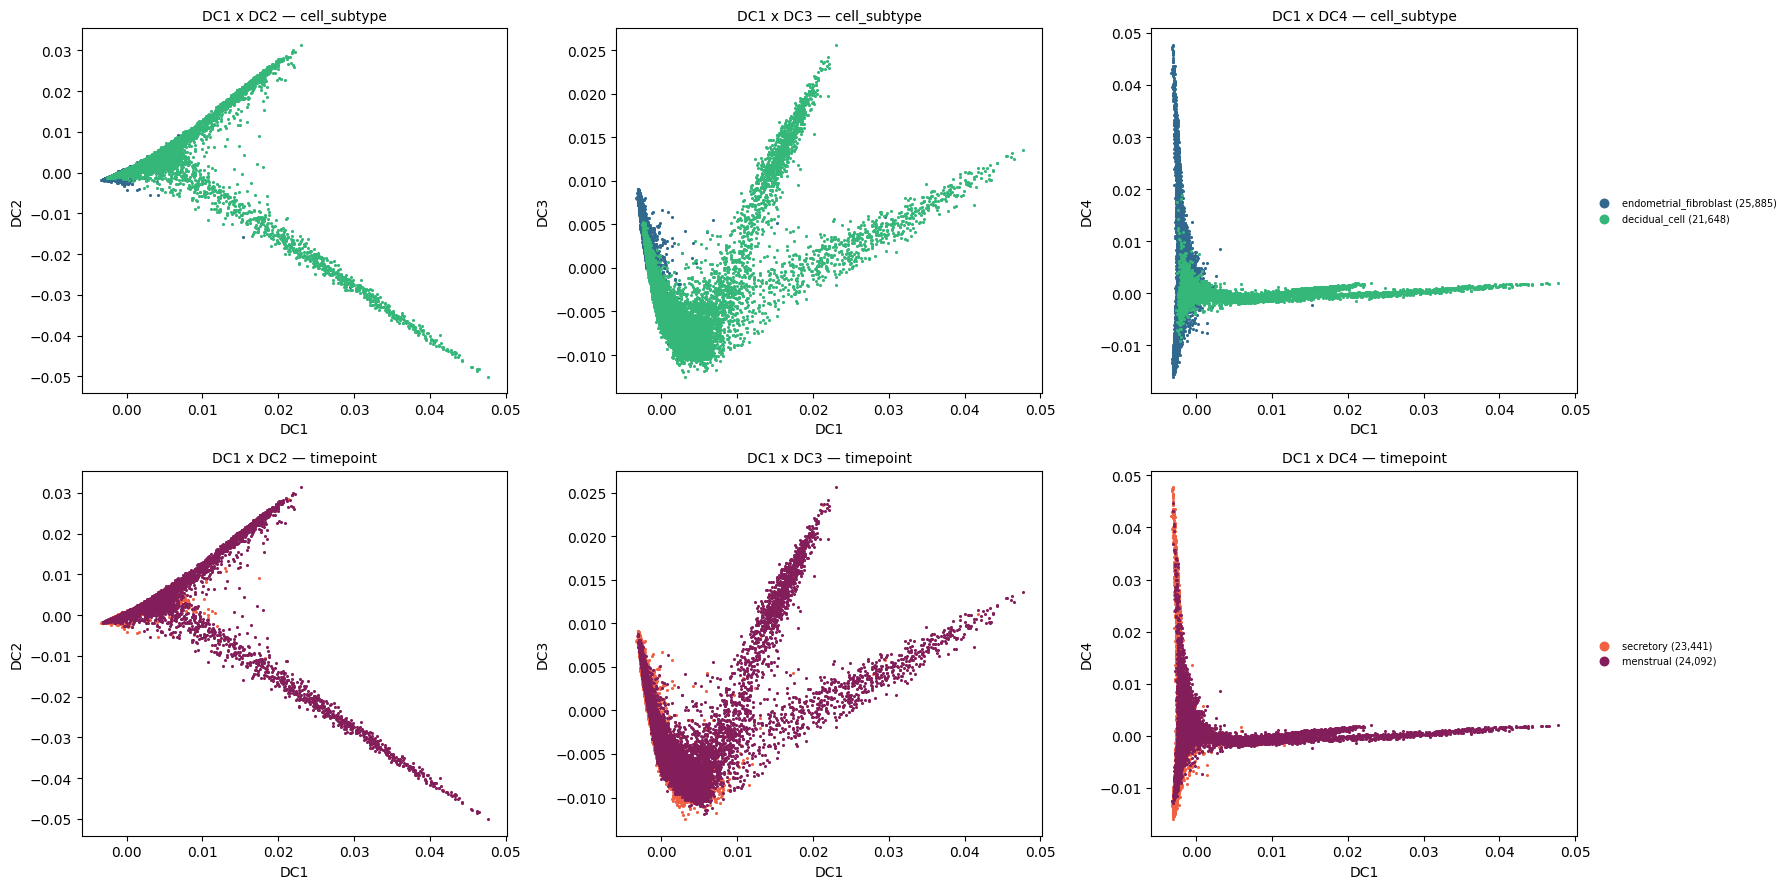

In [6]:
rank_sub = O.cell_subtype.map(RANK).to_numpy(float)
rows = []
for k in range(1, NDC+1):
    v = DM[:, k]; lo, hi = np.percentile(v, 2), np.percentile(v, 98)
    top = lambda m, col: ", ".join(f"{i} {100*x:.0f}%" for i, x in O.loc[m, col].value_counts(normalize=True).head(2).items())
    r = float(spearmanr(v, rank_sub).statistic)
    rows.append(dict(DC=f"DC{k}", rho_subtype_rank=round(r,3), early_end=("max" if r < 0 else "min"),
                     low_tail=top(v<=lo,"cell_subtype")+"  |  "+top(v<=lo,"timepoint"),
                     high_tail=top(v>=hi,"cell_subtype")+"  |  "+top(v>=hi,"timepoint")))
ORIENT = pd.DataFrame(rows).set_index("DC"); display(ORIENT)
BEST = ORIENT.rho_subtype_rank.abs().idxmax(); BEST_DC = int(BEST[2:]); EARLY = ORIENT.loc[BEST, "early_end"]
print(f"\nstrongest differentiation axis: {BEST} (rho {ORIENT.loc[BEST,'rho_subtype_rank']:+.3f}) -> early end is its {EARLY.upper()}")

def dc_panels(pairs=None, mark=None):
    pairs = pairs or [(BEST_DC, k) for k in range(1, min(NDC, 5)+1) if k != BEST_DC][:3]
    fig, axes = plt.subplots(2, len(pairs), figsize=(6*len(pairs), 9), squeeze=False)
    for j,(x,y) in enumerate(pairs):
        for i,(cmap_,col) in enumerate(((PAL,"cell_subtype"),(TPAL,"timepoint"))):
            ax = axes[i][j]
            for cat in [s for s in (SUBORDER if col=="cell_subtype" else TPORDER) if s in set(O[col])]:
                m = (O[col]==cat).to_numpy(); ax.scatter(DM[m,x], DM[m,y], s=1.5, c=[cmap_[cat]], label=f"{cat} ({m.sum():,})", rasterized=True)
            if mark:
                for bc, mk, cl in mark:
                    p = O.index.get_loc(bc); ax.scatter(DM[p,x], DM[p,y], s=180, marker=mk, c=cl, edgecolor="k", lw=.9, zorder=6)
            ax.set_xlabel(f"DC{x}"); ax.set_ylabel(f"DC{y}"); ax.set_title(f"DC{x} x DC{y} — {col}", fontsize=10)
            if j == len(pairs)-1: ax.legend(fontsize=7, markerscale=5, loc="center left", bbox_to_anchor=(1.02,.5), frameon=False)
    fig.tight_layout(); return fig
_ = dc_panels()

## 5 — **choose the root** (edit this cell)

Default: the most extreme **secretory `endometrial_fibroblast`** at the early pole — the earlier phase and the earlier subtype. `root_grid()` shows the 2×2 alternatives. If `human_dec_subclusters.csv` exists it is joined here as `dec_subcluster` for the finer violins in §9 (it does not affect the root or the gates).

all root options (depth 1.00 = deepest into the early pole):


,subtype,timepoint,pool,barcode,depth_into_early_pole,has_coords
0,endometrial_fibroblast,secretory,17891,GATCACACAACGATCT-1-secretory_mck6c,1.0000,True
1,endometrial_fibroblast,menstrual,7994,TACAGGTAGGTCACTT-1-menstrual_mck5a,0.9999,False
2,decidual_cell,secretory,5550,ATGGGAGAGGAATTAC-1-secretory_mck6a,0.9711,False
3,decidual_cell,menstrual,16098,GCAACATGTTCCATTT-1-menstrual_mck5a,0.9491,False



root: GATCACACAACGATCT-1-secretory_mck6c
  {'dc': None, 'side': 'early', 'pct': 0, 'timepoint': 'secretory', 'subtype': 'endometrial_fibroblast'} -> DC1 min, pool 17891
  subtype=endometrial_fibroblast  timepoint=secretory  sample=secretory_mck6c  section=secretory_mck6c__A
  depth into early pole of DC1: 1.0000
PASS  root is at the early end of the main axis (depth > 0.9)   [True]
PASS  root is a fibroblast   [True]
PASS  root is secretory (the earlier phase)   [True]  a menstrual root is allowed but inverts the phase gate by construction
joined decidual subclusters: {'endometrial_fibroblast': 25885, 'dec_0': 15076, 'dec_1': 4678, 'dec_2': 1054, 'dec_3': 840}


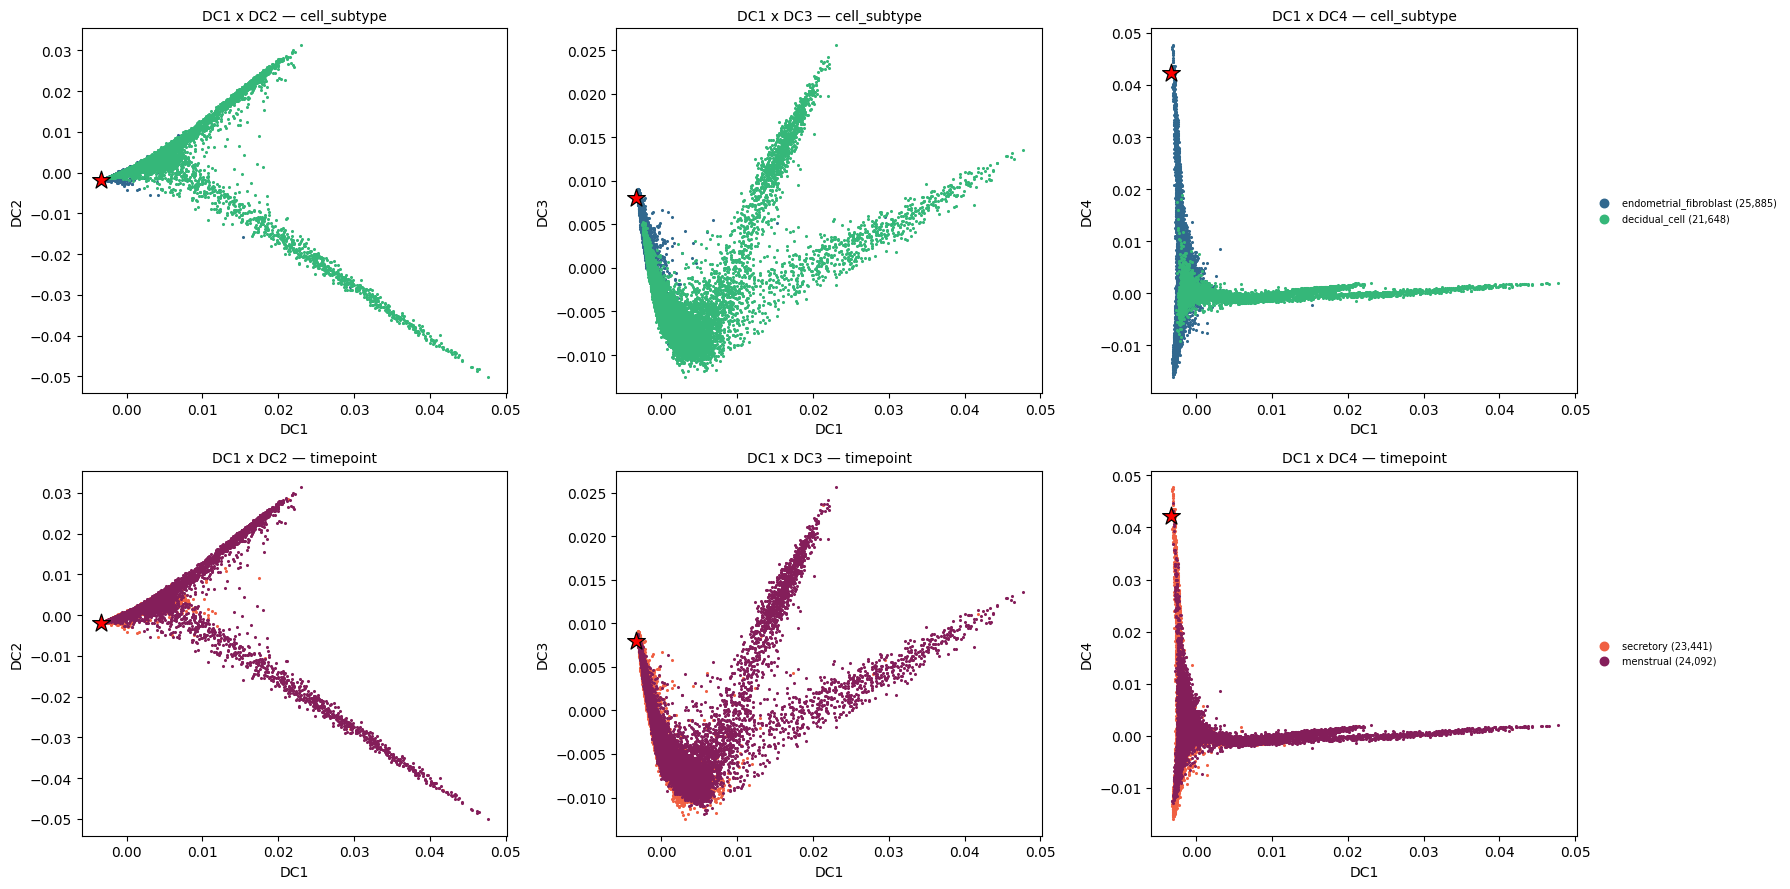

In [7]:
def _resolve(dc=None, side="early", pct=0, subtype=None, timepoint=None):
    dc = dc or BEST_DC
    side = (ORIENT.loc[f"DC{dc}", "early_end"] if side == "early" else side)
    m = np.ones(len(O), bool)
    if subtype   is not None: m &= (O.cell_subtype == subtype).to_numpy()
    if timepoint is not None: m &= (O.timepoint == timepoint).to_numpy()
    if not m.any(): return None
    v = DM[m, dc]
    if pct == 0: j = int(np.argmax(v)) if side == "max" else int(np.argmin(v))
    else:
        q = np.percentile(v, 100-pct if side == "max" else pct); j = int(np.argmin(np.abs(v - q)))
    idx = int(np.flatnonzero(m)[j]); return O.index[idx], idx, int(m.sum()), dc, side

def root_grid(dc=None, side="early", pct=0, min_pool=50):
    out = []
    for s in [x for x in SUBORDER if x in set(O.cell_subtype)]:
        for t in [x for x in TPORDER if x in set(O.timepoint)]:
            r = _resolve(dc, side, pct, s, t)
            if r and r[2] >= min_pool:
                bc, idx, n, d, sd = r
                out.append(dict(subtype=s, timepoint=t, pool=n, barcode=bc,
                    depth_into_early_pole=round(float((DM[:,d] < DM[idx,d]).mean() if sd=="max" else (DM[:,d] > DM[idx,d]).mean()),4),
                    has_coords=bool(np.isfinite(pd.to_numeric(O.x_um_qc.iloc[idx], errors="coerce")))))
    return pd.DataFrame(out).sort_values("depth_into_early_pole", ascending=False).reset_index(drop=True)
print("all root options (depth 1.00 = deepest into the early pole):"); display(root_grid())

# ------------------------------------------------------------------ EDIT HERE
ROOT = dict(dc=None, side="early", pct=0, timepoint="secretory", subtype="endometrial_fibroblast")
ROOT_BARCODE = None
# ------------------------------------------------------------------
if ROOT_BARCODE:
    assert ROOT_BARCODE in O.index; ROOT_BC, ROOT_IDX = ROOT_BARCODE, int(O.index.get_loc(ROOT_BARCODE)); ROOT_DESC = f"explicit barcode {ROOT_BARCODE}"
else:
    ROOT_BC, ROOT_IDX, npool, dc_used, side_used = _resolve(**ROOT); ROOT_DESC = f"{ROOT} -> DC{dc_used} {side_used}, pool {npool}"
depth = float((DM[:,BEST_DC] < DM[ROOT_IDX,BEST_DC]).mean() if EARLY=="max" else (DM[:,BEST_DC] > DM[ROOT_IDX,BEST_DC]).mean())
print(f"\nroot: {ROOT_BC}\n  {ROOT_DESC}\n  subtype={O.cell_subtype.iloc[ROOT_IDX]}  timepoint={O.timepoint.iloc[ROOT_IDX]}  "
      f"sample={O['sample'].iloc[ROOT_IDX]}  section={O.tissue_section.iloc[ROOT_IDX]}\n  depth into early pole of {BEST}: {depth:.4f}")
_ = dc_panels(mark=[(ROOT_BC, "*", "red")])
verify("root is at the early end of the main axis (depth > 0.9)", depth > 0.9)
verify("root is a fibroblast", O.cell_subtype.iloc[ROOT_IDX] == "endometrial_fibroblast")
verify("root is secretory (the earlier phase)", O.timepoint.iloc[ROOT_IDX] == "secretory",
       note="a menstrual root is allowed but inverts the phase gate by construction")

# optional finer decidual labels for the violins
if SUBCL.exists():
    sub = pd.read_csv(SUBCL, index_col=0)
    col = "leiden_0.3"   # the resolution chosen in the subclustering sweep (4 clusters, best bootstrap ARI); the CSV holds every resolution tried
    assert col in sub.columns, f"{col} not in {list(sub.columns)}"
    O["dec_subcluster"] = np.where(O.cell_subtype == "decidual_cell", "dec_" + sub[col].reindex(O.index).astype("Int64").astype(str), O.cell_subtype)
    print("joined decidual subclusters:", O.dec_subcluster.value_counts().to_dict())
else:
    O["dec_subcluster"] = O.cell_subtype; print("no decidual subcluster file at", SUBCL, "- violins use cell_subtype only")

## 6 — DPT and Palantir from that root

In [8]:
import palantir
res = pd.DataFrame(index=O.index); res.index.name = "cell"
for c in ("cell_subtype","timepoint","sample","tissue_section","spatial_qc_reason"): res[c] = O[c].to_numpy()
res["x_um"] = pd.to_numeric(O.x_um_qc, errors="coerce").to_numpy(float)
res["y_um"] = pd.to_numeric(O.y_um_qc, errors="coerce").to_numpy(float)

a.uns["iroot"] = ROOT_IDX
sc.tl.dpt(a, n_dcs=min(10, DM.shape[1]))
res["dpt"] = a.obs["dpt_pseudotime"].to_numpy(float)
verify("DPT is 0 at the root", float(res.dpt.iloc[ROOT_IDX]) == 0.0)
verify("DPT finite everywhere", bool(np.isfinite(res.dpt).all()), note=f"{int((~np.isfinite(res.dpt)).sum())} non-finite (disconnected cells)")

dmap = palantir.utils.run_diffusion_maps(pd.DataFrame(a.obsm["X_scVI"], index=O.index), n_components=10, knn=30)
ms   = palantir.utils.determine_multiscale_space(dmap)
pr   = palantir.core.run_palantir(ms, ROOT_BC, num_waypoints=1200, n_jobs=8, use_early_cell_as_start=True, seed=SEED)
res["palantir"] = pr.pseudotime.reindex(O.index).to_numpy(float)
verify("Palantir is 0 at the root (root honoured)", float(res.palantir.iloc[ROOT_IDX]) == 0.0,
       note="False = use_early_cell_as_start was ignored and Palantir re-picked its own start")
verify("Palantir minimum IS the root", res.palantir.idxmin() == ROOT_BC)
print("spearman(DPT, Palantir) =", round(float(spearmanr(res.dpt, res.palantir, nan_policy="omit").statistic), 4))
if "dpt_pseudotime_aug29" in O:
    old = pd.to_numeric(O.dpt_pseudotime_aug29, errors="coerce").to_numpy(float); m = np.isfinite(old)
    print("agreement with the Aug-29 moscot/CellRank DPT on the object (informational only):",
          {k: round(float(spearmanr(res[k][m], old[m]).statistic), 3) for k in ("dpt","palantir")})

PASS  DPT is 0 at the root   [True]
PASS  DPT finite everywhere   [True]  0 non-finite (disconnected cells)
Sampling and flocking waypoints...
Time for determining waypoints: 0.0004481673240661621 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.4160601814587911 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9999
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
FAIL  Palantir is 0 at the root (root honoured)   [False]  False = use_early_cell_as_start was ignored and Palantir re-picked its own start
FAIL  Palantir minimum IS the root   [False]
spearman(DPT, Palantir) = 0.7483
agreement with the Aug-29 moscot/CellRank DPT on the object (informational only): {'dpt': 0.829, 'palantir': 0.793}


## 7 — quantile normalisation

PASS  quantile transform preserves ordering exactly   [True]


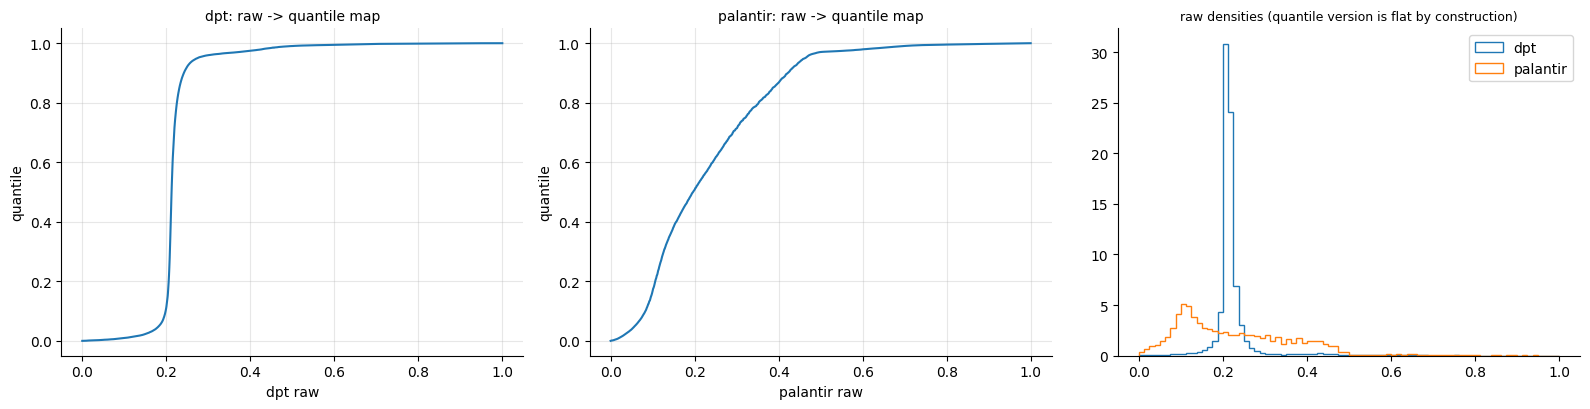

In [9]:
for m in ("dpt","palantir"):
    res[f"{m}_q"]    = res[m].rank(pct=True)
    res[f"{m}_qsec"] = res.groupby("tissue_section", observed=True)[m].rank(pct=True)
verify("quantile transform preserves ordering exactly", float(spearmanr(res.palantir, res.palantir_q, nan_policy="omit").statistic) == 1.0)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, m in zip(axes[:2], ("dpt","palantir")):
    v = np.sort(res[m].dropna()); ax.plot(v, np.linspace(0,1,len(v)), lw=1.5); ax.grid(alpha=.3)
    ax.set_xlabel(f"{m} raw"); ax.set_ylabel("quantile"); ax.set_title(f"{m}: raw -> quantile map", fontsize=10)
for m, c in (("dpt","C0"),("palantir","C1")): axes[2].hist(res[m].dropna(), bins=80, histtype="step", density=True, color=c, label=m)
axes[2].legend(); axes[2].set_title("raw densities (quantile version is flat by construction)", fontsize=9); fig.tight_layout()

## 8 — orientation gates (REFUSED, never flipped)

Three checks: fibroblasts before decidual cells; within decidual cells, secretory before menstrual; and the pooled phase correlation for reference (composition-confounded, as in mouse).

In [10]:
def gates(pt):
    sr = O.cell_subtype.map(RANK).to_numpy(float); tr = O.timepoint.map(TPRANK).to_numpy(float); ok = np.isfinite(pt)
    dec = ok & (O.cell_subtype == "decidual_cell").to_numpy(); fib = ok & ~dec
    rho = lambda m, y: round(float(spearmanr(pt[m], y[m]).statistic), 4) if m.sum() > 50 else None
    med = pd.Series(pt, index=O.index).groupby(O.cell_subtype).median()
    d = dict(rho_subtype=rho(ok, sr), rho_phase_all=rho(ok, tr), rho_phase_decidual_only=rho(dec, tr), rho_phase_fibroblasts_only=rho(fib, tr),
             median_fib=round(float(med["endometrial_fibroblast"]),4), median_dec=round(float(med["decidual_cell"]),4),
             frac_dec_above_fib_median=round(float((pt[dec] > med["endometrial_fibroblast"]).mean()),3))
    bad = (d["rho_subtype"] or 0) <= 0 or (d["rho_phase_decidual_only"] or 0) <= 0
    d["verdict"] = "REFUSED — orientation gate failed; NOT flipped, choose another root" if bad else "OK"
    return d
GATES = {m: gates(res[m].to_numpy()) for m in ("dpt","palantir")}; display(pd.DataFrame(GATES).T)
for m, g in GATES.items():
    verify(f"{m}: orientation", g["verdict"] == "OK", note=g["verdict"])
    verify(f"{m}: fibroblasts precede decidual cells", (g["rho_subtype"] or 0) > 0)
    verify(f"{m}: within decidual cells, secretory precedes menstrual", (g["rho_phase_decidual_only"] or 0) > 0,
           note="the check that the earlier human run only just cleared (rho 0.31 pooled)")

,rho_subtype,rho_phase_all,rho_phase_decidual_only,rho_phase_fibroblasts_only,median_fib,median_dec,frac_dec_above_fib_median,verdict
dpt,0.6818,0.3984,0.237,0.0839,0.2085,0.2218,0.945,OK
palantir,0.7904,0.474,0.2799,0.1511,0.1212,0.3294,0.994,OK


PASS  dpt: orientation   [True]  OK
PASS  dpt: fibroblasts precede decidual cells   [True]
PASS  dpt: within decidual cells, secretory precedes menstrual   [True]  the check that the earlier human run only just cleared (rho 0.31 pooled)
PASS  palantir: orientation   [True]  OK
PASS  palantir: fibroblasts precede decidual cells   [True]
PASS  palantir: within decidual cells, secretory precedes menstrual   [True]  the check that the earlier human run only just cleared (rho 0.31 pooled)


## 9 — violins, raw vs quantile

By subtype, by phase, by sample, and — if the subcluster file was found — by decidual subcluster.

median Palantir quantile by phase x subtype (pooled violins are composition-driven):


cell_subtype,decidual_cell,endometrial_fibroblast
timepoint,,
secretory,0.661,0.258
menstrual,0.795,0.327



decidual fraction per sample:


sample,secretory_mck6a,secretory_mck6b,secretory_mck6c,menstrual_mck5a,menstrual_mck5b,menstrual_mck5c
frac_decidual,0.234,0.232,0.25,0.666,0.671,0.667


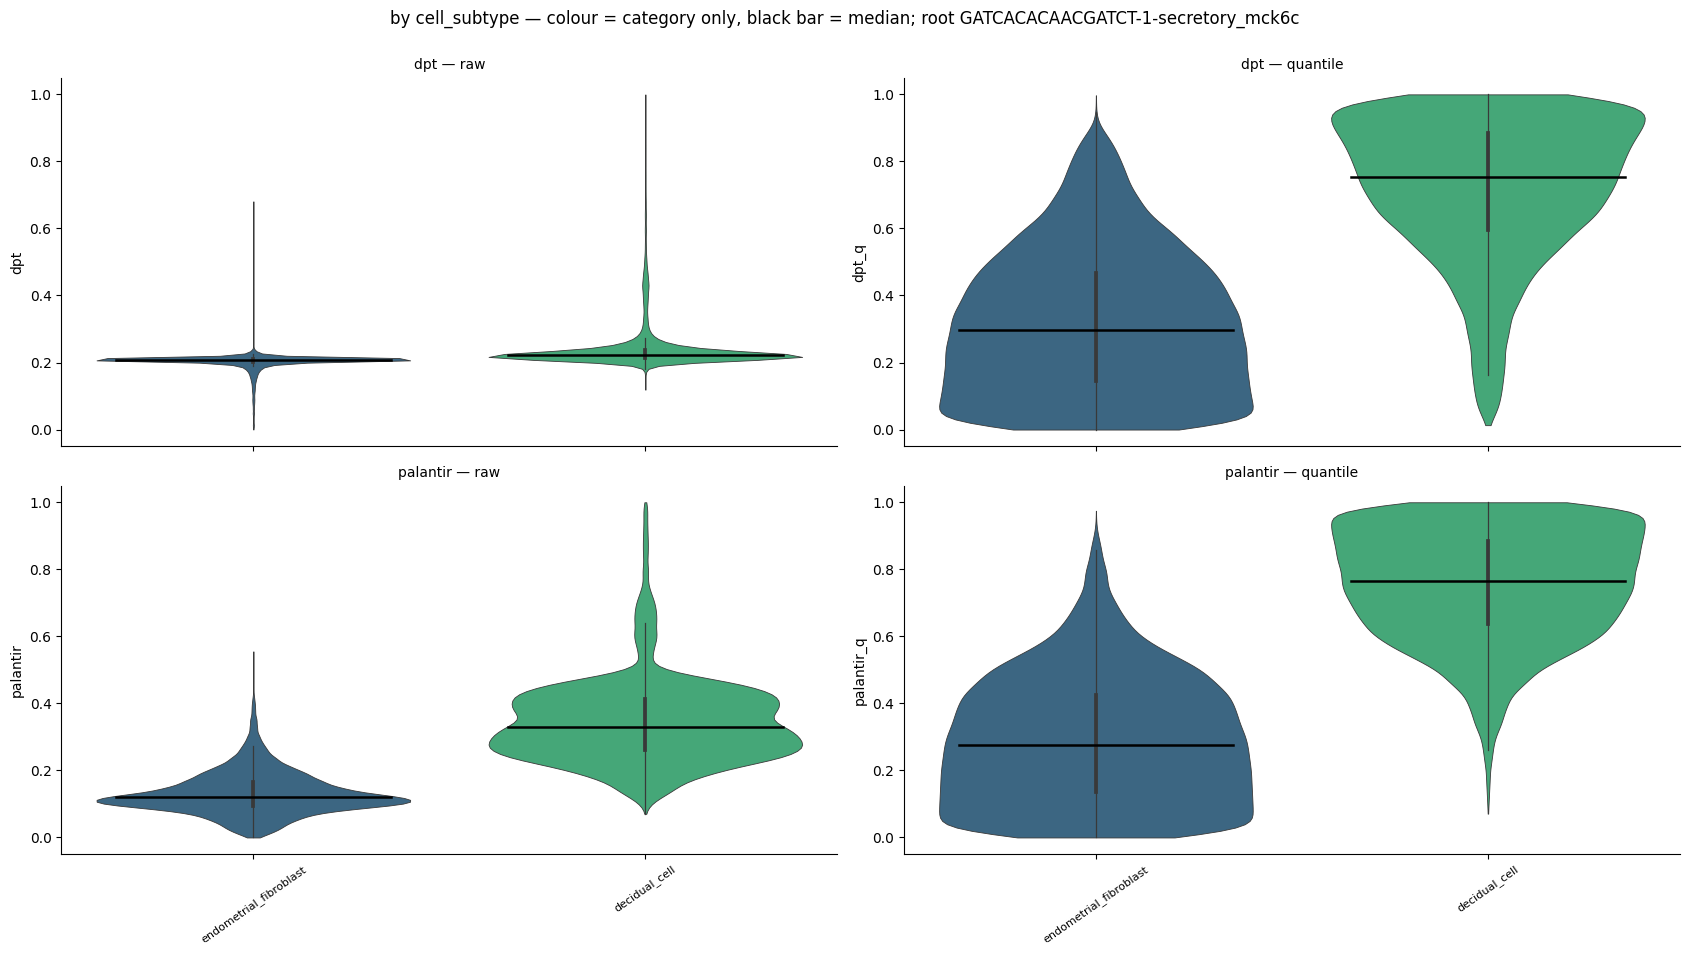

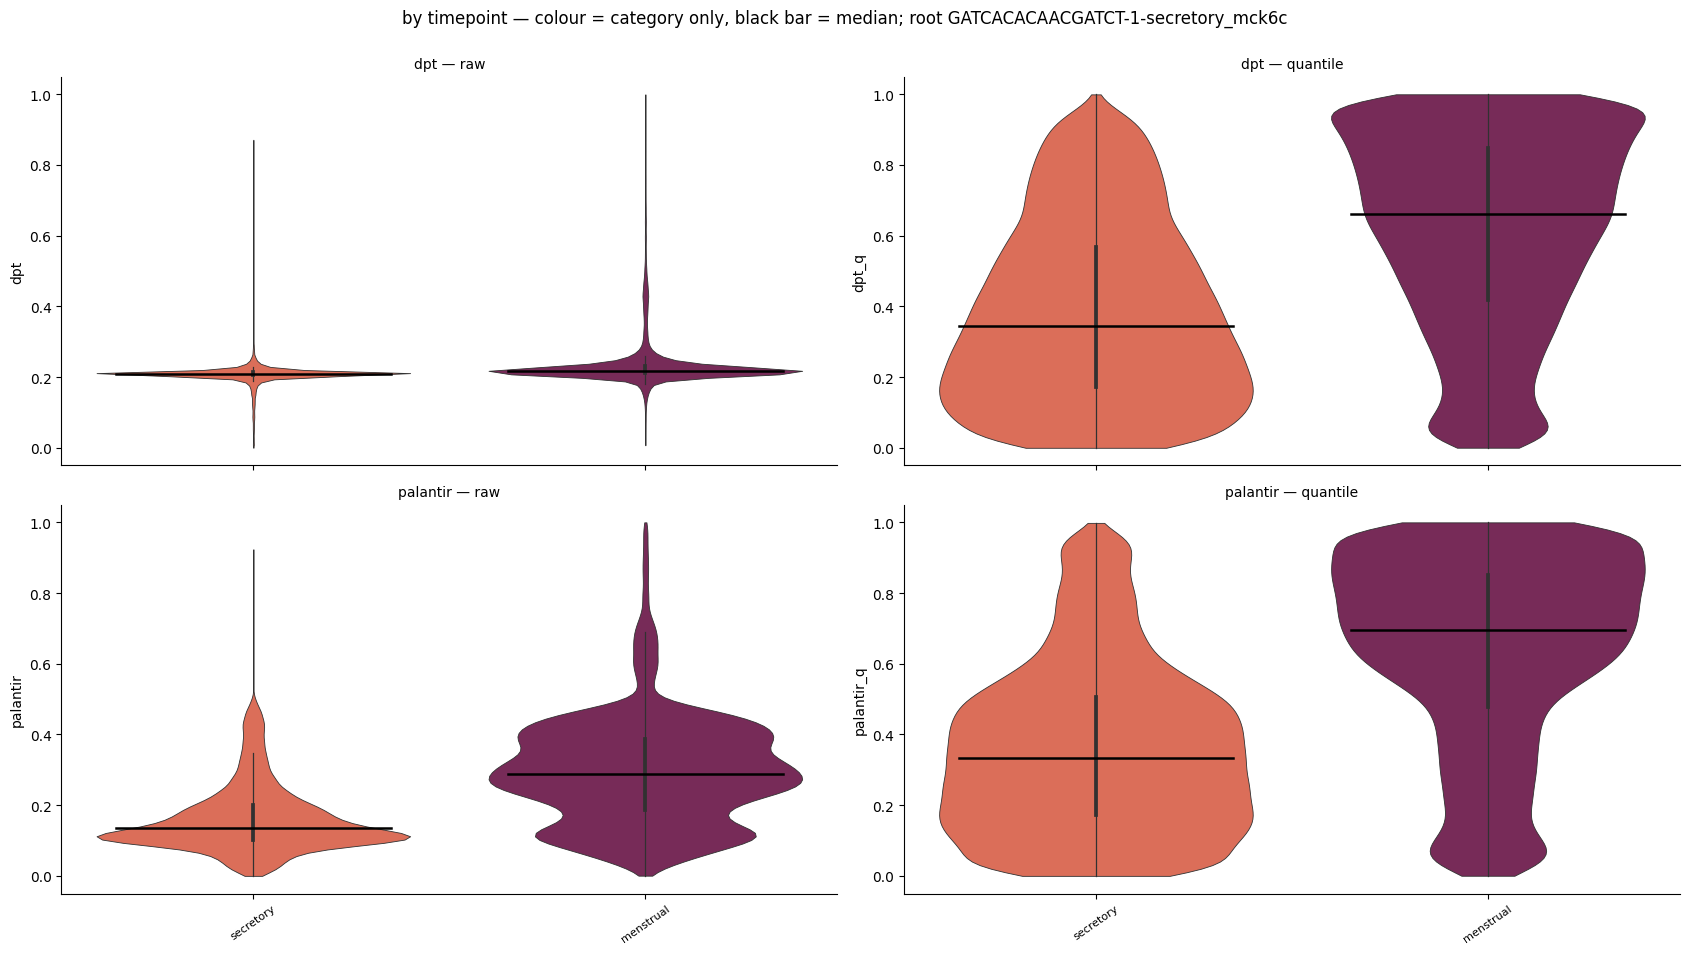

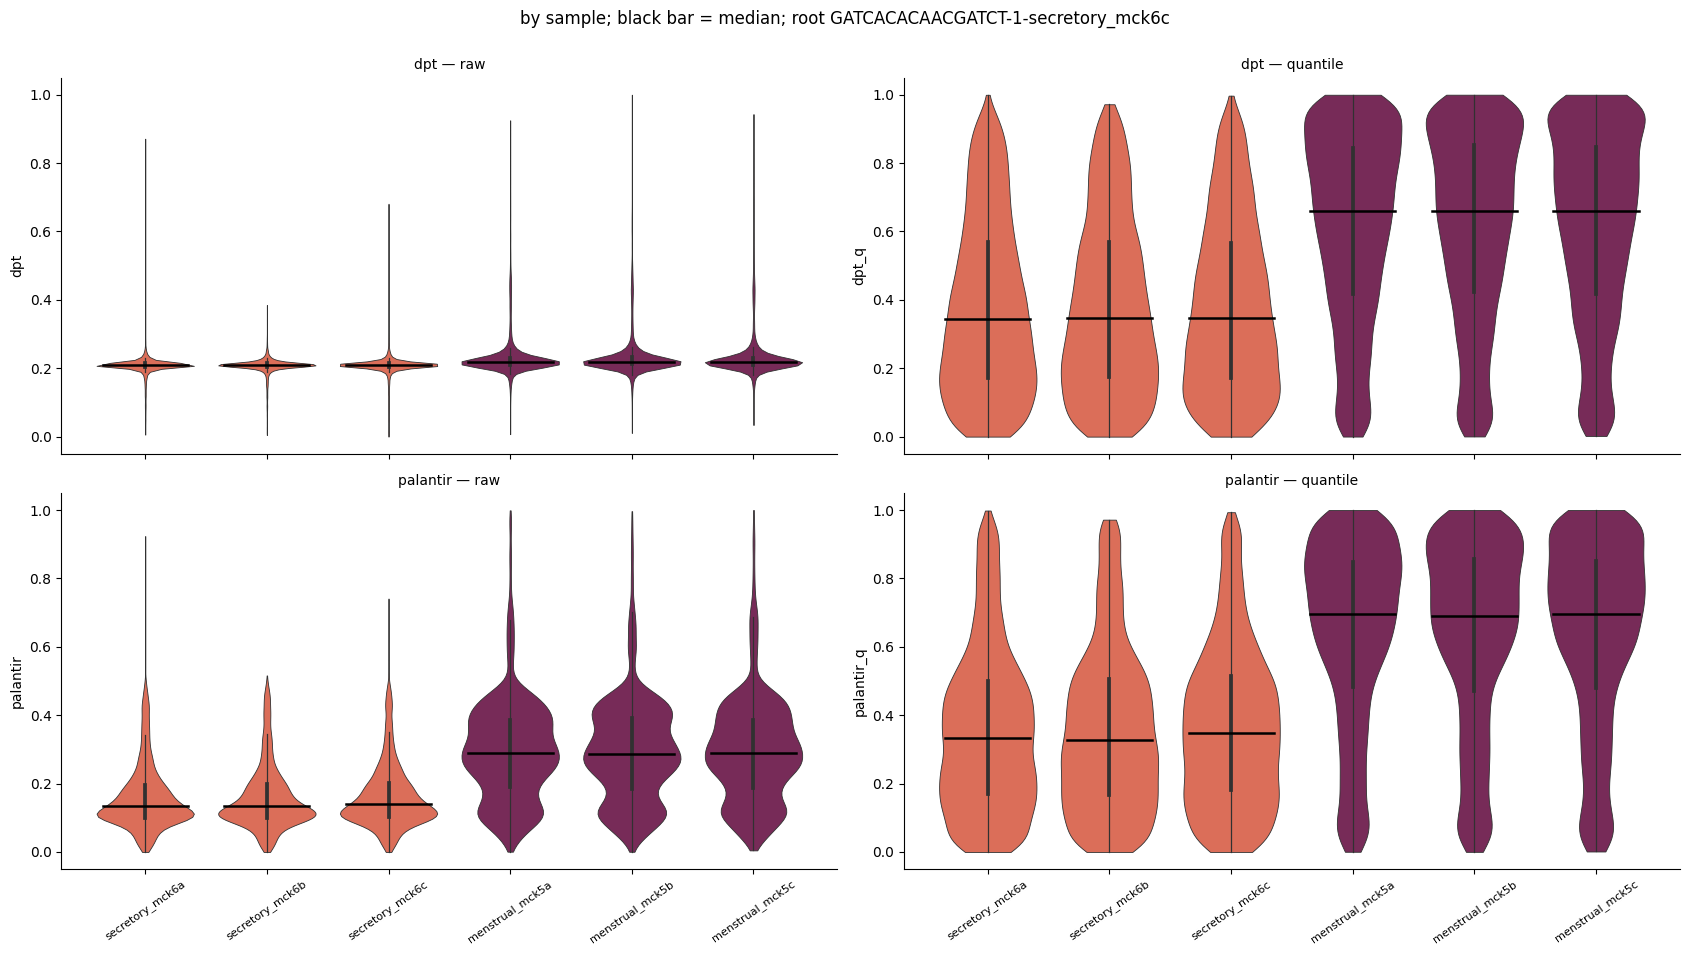

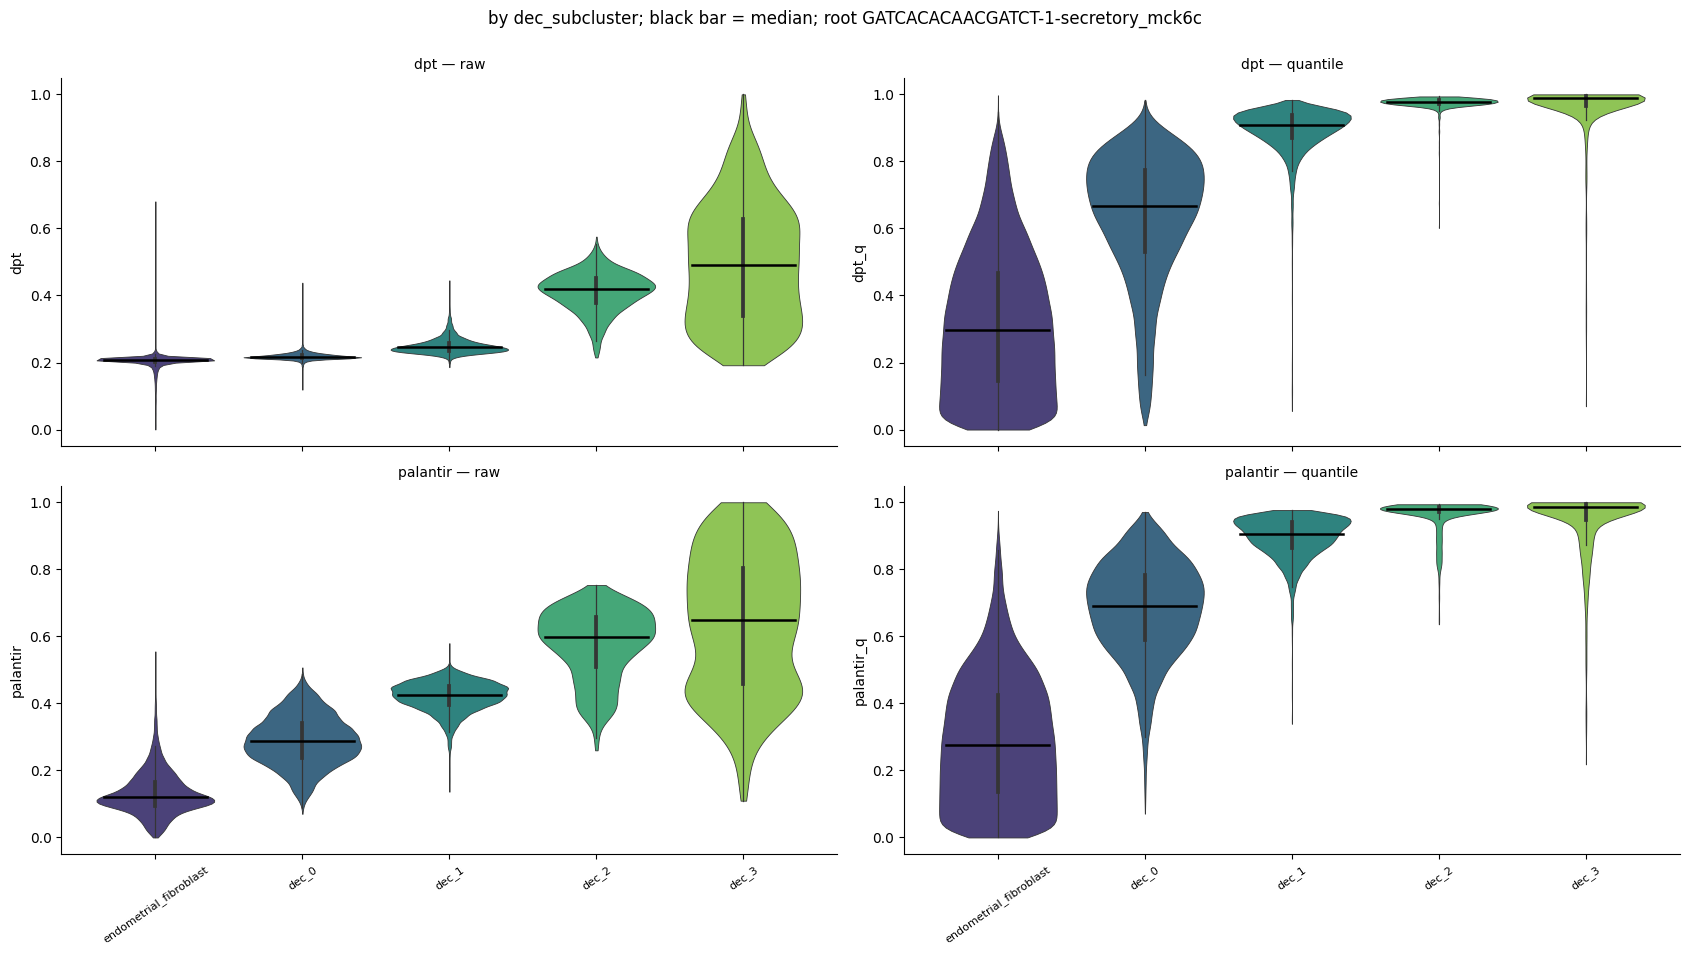

In [11]:
def violins(by):
    order = [s for s in (SUBORDER if by=="cell_subtype" else TPORDER) if s in set(res[by])]; pal = PAL if by=="cell_subtype" else TPAL
    fig, axes = plt.subplots(2, 2, figsize=(17, 9.5), sharex=True)
    for i, m in enumerate(("dpt","palantir")):
        for j, col in enumerate((m, f"{m}_q")):
            ax = axes[i][j]
            sns.violinplot(data=res, x=by, y=col, order=order, hue=by, hue_order=order, palette=pal, legend=False, cut=0, linewidth=.6, ax=ax)
            med = res.groupby(by, observed=True)[col].median()
            for k, cat in enumerate(order): ax.plot([k-.35,k+.35],[med[cat]]*2, c="k", lw=1.8, zorder=5)
            ax.set_title(f"{m} — {'quantile' if col.endswith('_q') else 'raw'}", fontsize=10); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35, labelsize=8)
    fig.suptitle(f"by {by} — colour = category only, black bar = median; root {ROOT_BC}", y=1.0); fig.tight_layout(); return fig
res["dec_subcluster"] = O.dec_subcluster.to_numpy()
_ = violins("cell_subtype"); _ = violins("timepoint")
SAMPLE_ORDER = [s for t in TPORDER for s in sorted(res["sample"].unique()) if s.startswith(t)]
def violins_by(by, order, pal):
    fig, axes = plt.subplots(2, 2, figsize=(17, 9.5), sharex=True)
    for i, m in enumerate(("dpt","palantir")):
        for j, col in enumerate((m, f"{m}_q")):
            ax = axes[i][j]
            sns.violinplot(data=res, x=by, y=col, order=order, hue=by, hue_order=order, palette=pal, legend=False, cut=0, linewidth=.6, ax=ax)
            med = res.groupby(by, observed=True)[col].median()
            for k, cat in enumerate(order): ax.plot([k-.35,k+.35],[med[cat]]*2, c="k", lw=1.8, zorder=5)
            ax.set_title(f"{m} — {'quantile' if col.endswith('_q') else 'raw'}", fontsize=10); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35, labelsize=8)
    fig.suptitle(f"by {by}; black bar = median; root {ROOT_BC}", y=1.0); fig.tight_layout(); return fig
_ = violins_by("sample", SAMPLE_ORDER, dict(zip(SAMPLE_ORDER, [TPAL[s.split("_")[0]] for s in SAMPLE_ORDER])))
if res.dec_subcluster.nunique() > 2:
    dorder = ["endometrial_fibroblast"] + sorted([x for x in res.dec_subcluster.unique() if x.startswith("dec_")])
    _ = violins_by("dec_subcluster", dorder, dict(zip(dorder, sns.color_palette("viridis", len(dorder)))))
print("median Palantir quantile by phase x subtype (pooled violins are composition-driven):")
display(res.pivot_table(index="timepoint", columns="cell_subtype", values="palantir_q", aggfunc="median", observed=True).reindex(TPORDER).round(3))
print("\ndecidual fraction per sample:"); display((res.groupby("sample").cell_subtype.apply(lambda s: (s=="decidual_cell").mean())).reindex(SAMPLE_ORDER).round(3).to_frame("frac_decidual").T)

## 10 — spatial: raw, quantile (global), quantile (within section)

One row per section (six: three menstrual, three secretory pucks, one section each).

33,247 of 47,533 cells have a QC'd coordinate | 6 sections | per timepoint: {t: len(v) for t, v in SEC_BY_TP.items()}


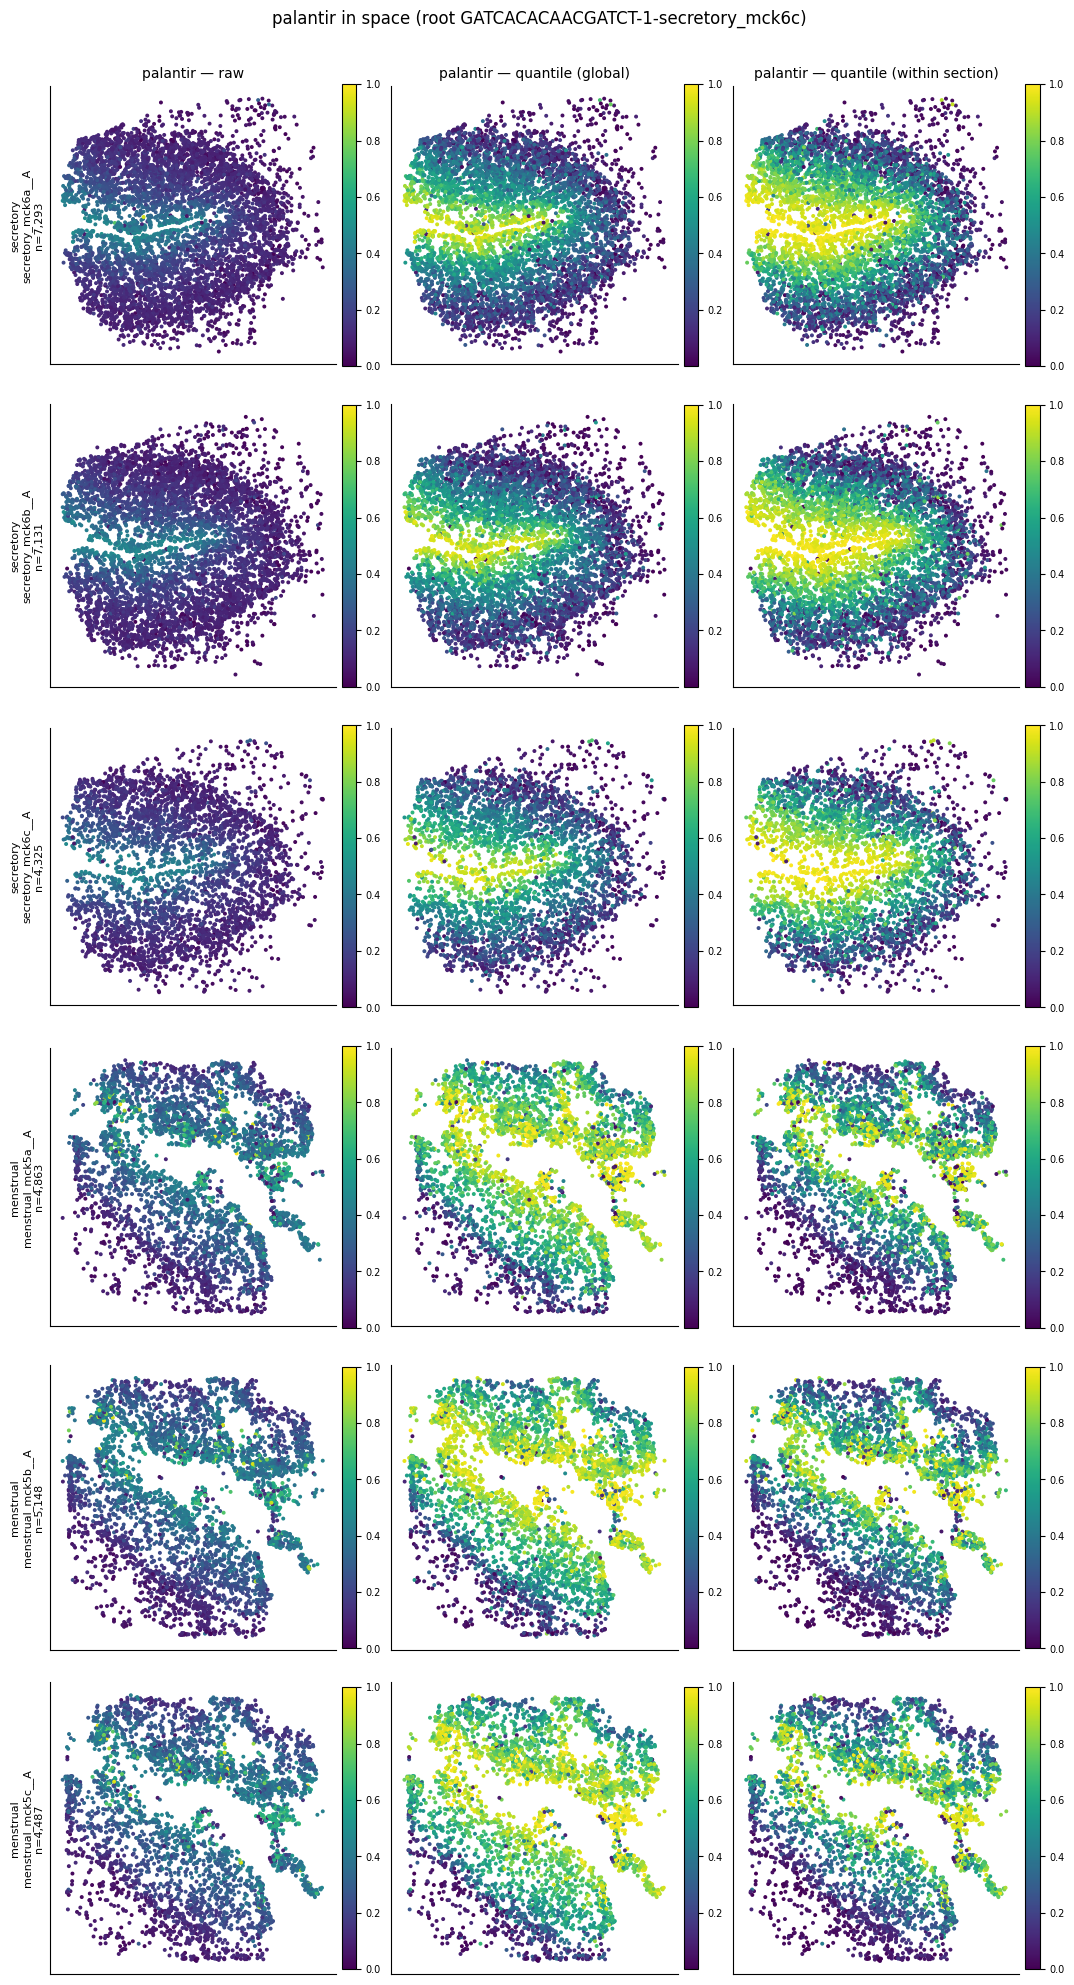

In [12]:
SP = res[np.isfinite(res.x_um) & res.tissue_section.notna()].copy()
SEC2TP = SP.groupby("tissue_section", observed=True).timepoint.first().to_dict()
secs = sorted(SP.tissue_section.unique(), key=lambda s: (TPRANK.get(SEC2TP[s], 99), s))
SEC_BY_TP = {t: [s for s in secs if SEC2TP[s]==t] for t in TPORDER if any(SEC2TP[s]==t for s in secs)}
print(f"{len(SP):,} of {len(res):,} cells have a QC'd coordinate | {len(secs)} sections | per timepoint: {{t: len(v) for t, v in SEC_BY_TP.items()}}")

def spatial_panels(method="palantir", cols=("","_q","_qsec"), per=3.6, s=3.4):
    labs = {"":"raw","_q":"quantile (global)","_qsec":"quantile (within section)"}
    fig, axes = plt.subplots(len(secs), len(cols), figsize=(per*len(cols), per*len(secs)*.92), squeeze=False)
    for i, sec in enumerate(secs):
        g = SP[SP.tissue_section==sec]
        for j, suf in enumerate(cols):
            ax = axes[i][j]; col = f"{method}{suf}"; vmin, vmax = ((SP[col].min(), SP[col].max()) if suf!="_qsec" else (0,1))
            sm = ax.scatter(g.x_um, g.y_um, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            if i==0: ax.set_title(f"{method} — {labs[suf]}", fontsize=10)
            if j==0: ax.set_ylabel(f"{SEC2TP[sec]}\n{sec}\nn={len(g):,}", fontsize=8)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"{method} in space (root {ROOT_BC})", y=1.0); fig.tight_layout(); return fig

def spatial_by_timepoint(method="palantir", suffix="_q", per=3.5, s=3.4):
    labs = {"":"raw","_q":"quantile (global)","_qsec":"quantile (within section)"}; col = f"{method}{suffix}"
    ncol = max(len(v) for v in SEC_BY_TP.values()); vmin, vmax = ((SP[col].min(), SP[col].max()) if suffix!="_qsec" else (0,1))
    fig, axes = plt.subplots(len(SEC_BY_TP), ncol, figsize=(per*ncol, per*len(SEC_BY_TP)*.95), squeeze=False)
    for i, (tp, sl) in enumerate(SEC_BY_TP.items()):
        for j in range(ncol):
            ax = axes[i][j]
            if j >= len(sl): ax.axis("off"); continue
            g = SP[SP.tissue_section==sl[j]]
            sm = ax.scatter(g.x_um, g.y_um, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{sl[j].replace(tp+'_','')}  n={len(g):,}", fontsize=8)
            if j==0: ax.set_ylabel(tp, fontsize=10)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"{method} — {labs[suffix]}, by timepoint (root {ROOT_BC})", y=1.0); fig.tight_layout(); return fig

_ = spatial_panels("palantir")

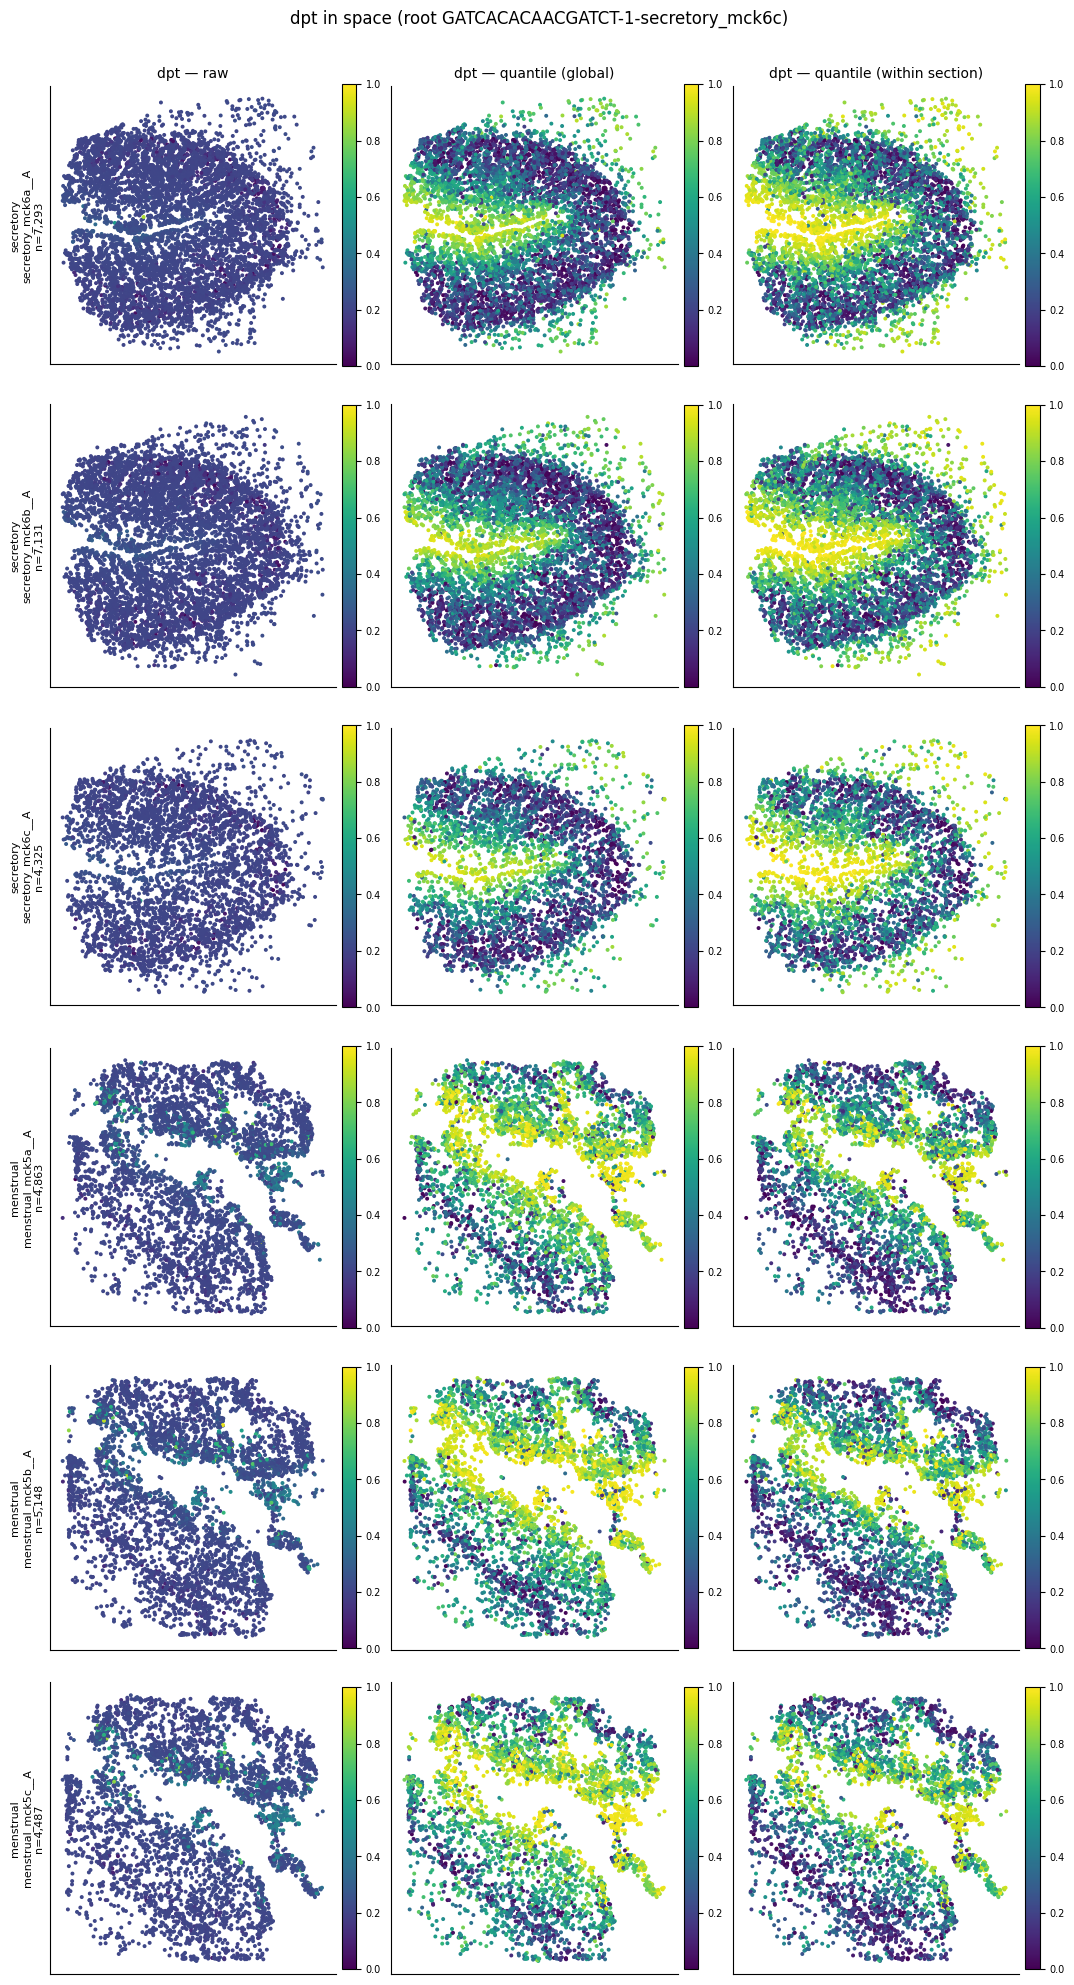

In [13]:
_ = spatial_panels("dpt")

In [ ]:
_ = spatial_by_timepoint("palantir", "_q"); _ = spatial_by_timepoint("palantir", "")

### Pseudotime vs isodepth per section

In [ ]:
if ISO.exists():
    with h5py.File(ISO, "r") as f:
        ic = [c for c in f["obs"].keys() if "isodepth" in c]; ICOL = "isodepth_consensus" if "isodepth_consensus" in ic else ic[0]
        iso = pd.Series(pd.to_numeric(read_elem(f[f"obs/{ICOL}"]), errors="coerce"), index=pd.Index(read_elem(f["obs/_index"])))
    SP["isodepth"] = iso.reindex(SP.index).to_numpy(float); m = np.isfinite(SP.isodepth)
    rows = [dict(section=sec, n=len(g), rho_palantir=round(float(spearmanr(g.palantir, g.isodepth).statistic),3),
                 rho_dpt=round(float(spearmanr(g.dpt, g.isodepth).statistic),3))
            for sec, g in SP[m].groupby("tissue_section", observed=True) if len(g) >= 100]
    display(pd.DataFrame(rows).set_index("section"))
else: print("isodepth object not found:", ISO)

## 11 — save

In [ ]:
tag = (ROOT_BARCODE or "_".join(str(ROOT.get(k)) for k in ("timepoint","subtype") if ROOT.get(k)) + f"_pct{ROOT['pct']}")
res["root_barcode"] = ROOT_BC; res["root_desc"] = ROOT_DESC
res.to_csv(OUT/f"pseudotime_{tag}.csv")
json.dump(dict(source=str(SRC), n_cells=int(len(res)), dropped="none", kept="all 47,533 cells",
               scvi=a.uns["scvi"], root_barcode=ROOT_BC, root_desc=ROOT_DESC, spec=(ROOT_BARCODE or ROOT),
               main_axis=BEST, early_end=EARLY, gates=GATES, palantir_version=palantir.__version__,
               use_early_cell_as_start=True, checks=[dict(label=l, ok=o, got=g) for l,o,g,_ in CHECKS]),
          open(OUT/f"pseudotime_{tag}_report.json","w"), indent=1, default=str)
bad = [l for l,o,_,_ in CHECKS if not o]
print("wrote", OUT/f"pseudotime_{tag}.csv"); print(f"{len(CHECKS)} checks | {len(bad)} FAILED" + (": "+"; ".join(bad) if bad else " — all passed"))